# Optimizing SBERT for Long-Text Clustering 

The experimental pipeline :

- **Datasets:** Amazon Reviews, BBC News, Fake–Real News
- **Sentence-embedding models:** BERT, RoBERTa, DistilBERT, ALBERT, MPNET
- **Long-text methods:** Default, Sentence-Level (SL), Block-Level (BL)
- **Long-sequence baselines:** Longformer, BigBird
- **Dimension reduction:** UMAP (5D for clustering, 2D for visualization)
- **Clustering:** K-Means and K-Medoids, each repeated across 20 random seeds
- **Metrics:** paper-labelled ACC (publisher code uses Rand Score), ARI, NMI, Silhouette, mapped weighted F1
- **Additional outputs:** Table 7 cosine similarities, Fig. 8 ACC charts, Fig. 9 BERT 2D UMAP plots, Fig. 10 model-correlation heatmap, runtime/memory/throughput tables, CSV/XLSX exports, and cached embeddings.


In [1]:
# 1) Environment verification
import sys
import platform
import torch

print("Python:", sys.version)
print("Executable:", sys.executable)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("XPU available:", torch.xpu.is_available())
if torch.xpu.is_available():
    print("GPU:", torch.xpu.get_device_name(0))


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Executable: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Scripts\python.exe
Platform: Windows-10-10.0.26200-SP0
PyTorch: 2.13.0+xpu
XPU available: True
GPU: Intel(R) Arc(TM) 140T GPU (16GB)


## 2) Configuration

The full experiment is computationally expensive because SL encodes every sentence separately and each clustering configuration is evaluated over 20 seeds. Embeddings are cached under `generated_results/embeddings`, so interrupted runs can resume without recomputing completed embeddings.


In [2]:
# %pip install matplotlib==3.8.4 seaborn==0.13.2

In [3]:
from pathlib import Path
import os, re, gc, time, json, warnings
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import psutil
import nltk
import matplotlib.pyplot as plt
import umap

from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import f1_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import Normalizer

from sentence_transformers import SentenceTransformer, models
from transformers import (
    AutoTokenizer, AutoModel,
    LongformerTokenizer, LongformerModel,
    BigBirdTokenizer, BigBirdModel,
)

# ---------- Project paths ----------
ROOT = Path.cwd()
if not (ROOT / "Datasets").exists():
    raise FileNotFoundError(
        "Run the notebook from C:\\Users\\Aadya Gupta\\Desktop\\nmims\\SEM_VII\\Project "
        "so that the Datasets folder is directly under the working directory."
    )

DATA_DIR = ROOT / "Datasets"
OUT_DIR = ROOT / "generated_results"
EMBED_DIR = OUT_DIR / "embeddings"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
for d in (OUT_DIR, EMBED_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Execution controls ----------
QUICK_TEST = False                # True = use a small sample for pipeline testing
QUICK_N = 100                     # rows/dataset when QUICK_TEST=True
RUN_FULL_EXPERIMENT = True        # Tables 3-5 style results, both clustering algorithms
RUN_TABLE7 = True                 # intra-class cosine similarities on Fake-Real dataset
RUN_VISUALIZATIONS = True         # Fig. 8, Fig. 9, Fig. 10 equivalents
RUN_SCALABILITY_BENCHMARKS = False  # Tables 6/8/9 style hardware-dependent benchmark
REUSE_CACHED_EMBEDDINGS = True

# Device. XPU is your Intel Arc GPU.
PREFERRED_DEVICE = "xpu"
if PREFERRED_DEVICE == "xpu" and torch.xpu.is_available():
    DEVICE = "xpu"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

# Longformer/BigBird sparse operators may not be available on every XPU build.
# If a forward pass fails, the helper automatically retries that embedding on CPU.
print("Selected device:", DEVICE)

UMAP_SEED = 42
CLUSTER_SEEDS = list(range(20))

DATASETS = {
    "amazon_5000": {"path": DATA_DIR / "amazon_5000.csv", "k": 5, "display": "Amazon"},
    "bbc_2250": {"path": DATA_DIR / "bbc_2250.csv", "k": 5, "display": "BBC News"},
    "Fake_3000": {"path": DATA_DIR / "Fake_3000.csv", "k": 2, "display": "Fake-Real News"},
}

MODEL_CONFIG = {
    "BERT": {
        "id": "sentence-transformers/bert-base-nli-mean-tokens",
        "max_seq": 128,
    },
    "RoBERTa": {
        "id": "sentence-transformers/nli-roberta-base-v2",
        "max_seq": 75,
    },
    "DistilBERT": {
        "id": "sentence-transformers/distilbert-base-nli-mean-tokens",
        "max_seq": 128,
    },
    "ALBERT": {
        "id": "sentence-transformers/paraphrase-albert-small-v2",
        "max_seq": 100,
    },
    "MPNET": {
        "id": "sentence-transformers/all-mpnet-base-v2",
        "max_seq": 128,
    },
    "LongFormer": {
        "id": "allenai/longformer-base-4096",
        "max_seq": 4096,
    },
    "BigBird": {
        "id": "google/bigbird-roberta-base",
        "max_seq": 4096,
    },
}

STANDARD_MODELS = ["BERT", "RoBERTa", "DistilBERT", "ALBERT", "MPNET"]
STANDARD_METHODS = ["Default", "SL", "BL"]

print("ROOT:", ROOT)
print("Output directory:", OUT_DIR)


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Selected device: xpu
ROOT: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project
Output directory: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\generated_results


In [4]:
# 3) Dataset validation + preprocessing (same regex logic as publisher code)
def remove_urls(text):
    text = str(text)
    return " ".join([c for c in text.split() if not urlparse(c).scheme])


def publisher_tokenizer(text):
    text = remove_urls(text)
    text = re.sub(r"([^a-zA-Z ?.'])+", "", text)
    text = re.sub(r"([^a-zA-Z])\1+", r"\1", text)
    text = re.sub(r"([.?)])", r"\1 ", text)
    return text


def load_dataset(dataset_key, n=None):
    cfg = DATASETS[dataset_key]
    df = pd.read_csv(cfg["path"])
    if "text" not in df.columns or "cluster" not in df.columns:
        raise ValueError(f"{cfg['path']} must contain text and cluster columns")
    if n is not None:
        # deterministic stratified-ish sample preserving original ordering after selection
        parts = []
        for _, g in df.groupby("cluster", sort=True):
            take = max(1, round(n * len(g) / len(df)))
            parts.append(g.sample(min(take, len(g)), random_state=42))
        df = pd.concat(parts).sort_index().head(n).copy()
    else:
        df = df.copy()
    df["text"] = df["text"].astype(str).map(publisher_tokenizer)
    return df.reset_index(drop=True)


summary_rows = []
for key, cfg in DATASETS.items():
    df = pd.read_csv(cfg["path"])
    summary_rows.append({
        "Dataset": key,
        "Rows": len(df),
        "Columns": ", ".join(df.columns),
        "Clusters": df["cluster"].nunique(),
        "Expected k": cfg["k"],
        "Mean words": round(df["text"].astype(str).str.split().str.len().mean(), 1),
    })

dataset_summary = pd.DataFrame(summary_rows)
display(dataset_summary)


,Dataset,Rows,Columns,Clusters,Expected k,Mean words
0,amazon_5000,5000,"cluster, title, text",5,5,75.5
1,bbc_2250,2225,"text, cluster",5,5,384.0
2,Fake_3000,3000,"text, cluster",2,2,405.7


## 4) Embedding implementation

The three proposed/default configurations follow the supplied `text_embedding.py` logic:

- **Default:** encode the document directly with the model-specific `max_seq_length`; excess text is truncated.
- **SL:** tokenize a document into sentences, encode each sentence, and average its sentence vectors.
- **BL:** tokenize without special tokens, split into blocks of `max_seq_length - 2`, manually add IDs 101/102 and zero-padding exactly as in the publisher code, mean-pool tokens per block, then average blocks.

Longformer uses the first-token representation; BigBird averages the last hidden state, matching the supplied publisher implementation.


In [5]:
# 4a) Device/cache helpers
def clear_accelerator_cache():
    gc.collect()
    if torch.xpu.is_available():
        try:
            torch.xpu.empty_cache()
        except Exception:
            pass
    if torch.cuda.is_available():
        try:
            torch.cuda.empty_cache()
        except Exception:
            pass


def cache_path(dataset_key, model_name, method, n_rows):
    tag = f"n{n_rows}"
    safe = f"{dataset_key}__{model_name}__{method}__{tag}.npy".replace("/", "_")
    return EMBED_DIR / safe


def build_sentence_transformer(model_id, device):
    # Mirrors publisher construction: Transformer + mean Pooling.
    word_model = models.Transformer(model_id)
    pooling_model = models.Pooling(
        word_model.get_word_embedding_dimension(),
        pooling_mode_mean_tokens=True,
        pooling_mode_cls_token=False,
        pooling_mode_max_tokens=False,
    )
    return SentenceTransformer(modules=[word_model, pooling_model], device=device)


def encode_default(documents, model_id, max_seq, device):
    model = build_sentence_transformer(model_id, device)
    model.max_seq_length = max_seq
    arr = model.encode(
        documents,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        device=device,
    )
    del model
    clear_accelerator_cache()
    return np.asarray(arr)


def encode_sl(documents, model_id, max_seq, device):
    model = build_sentence_transformer(model_id, device)
    model.max_seq_length = max_seq
    vectors = []
    for idx, document in enumerate(documents):
        sentences = [s for s in nltk.sent_tokenize(document) if len(s) > 10]
        if not sentences:
            # Publisher code prints/omits empty-sentence documents. Keeping row alignment is safer
            # for metric computation, so encode the complete document as fallback.
            sentences = [document]
        encoded = model.encode(
            sentences,
            batch_size=32,
            show_progress_bar=False,
            convert_to_numpy=True,
            device=device,
        )
        vectors.append(np.asarray(encoded).mean(axis=0))
        if (idx + 1) % 250 == 0 or idx + 1 == len(documents):
            print(f"SL encoded {idx + 1}/{len(documents)} documents")
    del model
    clear_accelerator_cache()
    return np.asarray(vectors)


def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output[0]
    mask = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * mask, 1) / torch.clamp(mask.sum(1), min=1e-9)


def encode_bl(documents, model_id, max_seq, device):
    # This intentionally reproduces the publisher's BL construction, including 101/102 and zero padding.
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id).to(device)
    model.eval()
    result = []

    for idx, document in enumerate(documents):
        encoded_input = tokenizer.encode_plus(document, add_special_tokens=False, return_tensors="pt")
        ids = encoded_input["input_ids"][0]
        masks = encoded_input["attention_mask"][0]
        id_chunks = list(ids.split(max_seq - 2))
        mask_chunks = list(masks.split(max_seq - 2))

        # Defensive fallback for an empty tokenization.
        if len(id_chunks) == 0:
            id_chunks = [torch.empty(0, dtype=torch.long)]
            mask_chunks = [torch.empty(0, dtype=torch.long)]

        for i in range(len(id_chunks)):
            # Exact publisher behavior rather than tokenizer-specific special-token IDs.
            id_chunks[i] = torch.cat([
                torch.tensor([101], dtype=torch.long),
                id_chunks[i].long(),
                torch.tensor([102], dtype=torch.long),
            ])
            mask_chunks[i] = torch.cat([
                torch.tensor([1], dtype=torch.long),
                mask_chunks[i].long(),
                torch.tensor([1], dtype=torch.long),
            ])
            missing = max_seq - id_chunks[i].shape[0]
            if missing > 0:
                id_chunks[i] = torch.cat([id_chunks[i], torch.zeros(missing, dtype=torch.long)])
                mask_chunks[i] = torch.cat([mask_chunks[i], torch.zeros(missing, dtype=torch.long)])

        input_ids = torch.stack(id_chunks).to(device)
        attention_mask = torch.stack(mask_chunks).to(device)

        with torch.inference_mode():
            model_output = model(input_ids=input_ids, attention_mask=attention_mask)
        block_vectors = mean_pooling(model_output, attention_mask)
        document_vector = block_vectors.mean(dim=0).detach().cpu().numpy()
        result.append(document_vector)

        del input_ids, attention_mask, model_output, block_vectors
        if (idx + 1) % 250 == 0 or idx + 1 == len(documents):
            print(f"BL encoded {idx + 1}/{len(documents)} documents")

    del model, tokenizer
    clear_accelerator_cache()
    return np.asarray(result)


def encode_longformer(documents, model_id, device):
    tokenizer = LongformerTokenizer.from_pretrained(model_id)
    model = LongformerModel.from_pretrained(model_id).to(device)
    model.eval()
    result = []
    for idx, document in enumerate(documents):
        inp = tokenizer(document, return_tensors="pt", truncation=True, max_length=4096)
        inp = {k: v.to(device) for k, v in inp.items()}
        with torch.inference_mode():
            output = model(**inp)
        vec = output.last_hidden_state[:, 0, :].squeeze(0).detach().cpu().numpy()
        result.append(vec)
        if (idx + 1) % 100 == 0 or idx + 1 == len(documents):
            print(f"LongFormer encoded {idx + 1}/{len(documents)} documents")
    del model, tokenizer
    clear_accelerator_cache()
    return np.asarray(result)


def encode_bigbird(documents, model_id, device):
    tokenizer = BigBirdTokenizer.from_pretrained(model_id)
    model = BigBirdModel.from_pretrained(model_id).to(device)
    model.eval()
    result = []
    for idx, document in enumerate(documents):
        inp = tokenizer(document, return_tensors="pt", truncation=True, max_length=4096)
        inp = {k: v.to(device) for k, v in inp.items()}
        with torch.inference_mode():
            output = model(**inp)
        vec = output.last_hidden_state.mean(dim=1).squeeze(0).detach().cpu().numpy()
        result.append(vec)
        if (idx + 1) % 100 == 0 or idx + 1 == len(documents):
            print(f"BigBird encoded {idx + 1}/{len(documents)} documents")
    del model, tokenizer
    clear_accelerator_cache()
    return np.asarray(result)


def compute_embeddings(documents, model_name, method, preferred_device=DEVICE):
    cfg = MODEL_CONFIG[model_name]
    model_id, max_seq = cfg["id"], cfg["max_seq"]

    def _run(device):
        print(f"Embedding: model={model_name}, method={method}, device={device}, n={len(documents)}")
        if method == "Default":
            return encode_default(documents, model_id, max_seq, device)
        if method == "SL":
            return encode_sl(documents, model_id, max_seq, device)
        if method == "BL":
            return encode_bl(documents, model_id, max_seq, device)
        if method == "LongFormer":
            return encode_longformer(documents, model_id, device)
        if method == "BigBird":
            return encode_bigbird(documents, model_id, device)
        raise ValueError(method)

    try:
        return _run(preferred_device)
    except RuntimeError as e:
        if preferred_device != "cpu":
            print("Accelerator execution failed; retrying this embedding on CPU.")
            print("Original error:", repr(e))
            clear_accelerator_cache()
            return _run("cpu")
        raise


def get_embeddings(dataset_key, model_name, method, df):
    path = cache_path(dataset_key, model_name, method, len(df))
    if REUSE_CACHED_EMBEDDINGS and path.exists():
        print("Loading cached:", path.name)
        return np.load(path)
    raw = compute_embeddings(df["text"].tolist(), model_name, method)
    normalized = Normalizer().fit_transform(raw)
    np.save(path, normalized.astype(np.float32))
    print("Saved:", path)
    return normalized


In [6]:
# 5) UMAP + clustering + evaluation 
def umap_reduce_5d(data_points):
    reducer = umap.UMAP(
        n_neighbors=70,
        n_components=5,
        metric="euclidean",
        min_dist=0.9,
        random_state=UMAP_SEED,
        transform_seed=UMAP_SEED,
    )
    return reducer.fit_transform(data_points)


def mapped_weighted_f1(actual, predicted, n_clusters):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    unique_actual = np.unique(actual)
    unique_pred = np.unique(predicted)
    n = max(n_clusters, len(unique_actual), len(unique_pred))
    cost = np.zeros((n, n), dtype=float)
    for i in range(len(unique_actual)):
        for j in range(len(unique_pred)):
            cost[i, j] = -np.sum((actual == unique_actual[i]) & (predicted == unique_pred[j]))
    row_ind, col_ind = linear_sum_assignment(cost)
    mapping = {}
    for i, j in zip(row_ind, col_ind):
        if i < len(unique_actual) and j < len(unique_pred):
            mapping[unique_pred[j]] = unique_actual[i]
    # For completeness if a predicted ID was unmatched.
    fallback = unique_actual[0]
    mapped = np.array([mapping.get(x, fallback) for x in predicted])
    return f1_score(actual, mapped, average="weighted")


def cluster_once(data_points, labels, k, algorithm, seed):
    start = time.time()
    if algorithm == "K-Means":
        estimator = KMeans(n_clusters=k, init="random", n_init=10, random_state=seed)
        predicted = estimator.fit_predict(data_points)
    elif algorithm == "K-Medoids":
        estimator = KMedoids(n_clusters=k, random_state=seed, metric="euclidean")
        predicted = estimator.fit_predict(data_points)
    else:
        raise ValueError(algorithm)

    acc_paper = metrics.rand_score(labels, predicted)
    ari = metrics.adjusted_rand_score(labels, predicted)
    nmi = metrics.normalized_mutual_info_score(labels, predicted, average_method="geometric")
    sil = silhouette_score(data_points, predicted)
    f1 = mapped_weighted_f1(labels, predicted, k)
    return {
        "ACC": acc_paper,
        "ARI": ari,
        "NMI": nmi,
        "SIL": sil,
        "F1": f1,
        "ClusterRunTime": time.time() - start,
    }


def evaluate_20_runs(data_points, labels, k, algorithm):
    rows = [cluster_once(data_points, labels, k, algorithm, seed) for seed in CLUSTER_SEEDS]
    all_runs = pd.DataFrame(rows)
    means = all_runs.mean(numeric_only=True).to_dict()
    stds = all_runs.std(numeric_only=True, ddof=0).to_dict()  # np.std in publisher code uses ddof=0
    return all_runs, means, stds


In [7]:
# 6) Run full experiment
all_seed_rows = []
summary_rows = []
embedding_perf_rows = []

if RUN_FULL_EXPERIMENT:
    for dataset_key, dcfg in DATASETS.items():
        df = load_dataset(dataset_key, QUICK_N if QUICK_TEST else None)
        labels = df["cluster"].to_numpy()
        print("\n" + "=" * 90)
        print(dataset_key, "rows=", len(df), "k=", dcfg["k"])
        print("=" * 90)

        configurations = [(m, meth) for m in STANDARD_MODELS for meth in STANDARD_METHODS]
        configurations += [("LongFormer", "LongFormer"), ("BigBird", "BigBird")]

        for model_name, method in configurations:
            process = psutil.Process(os.getpid())
            t0 = time.time()
            embeddings = get_embeddings(dataset_key, model_name, method, df)
            embedding_seconds = time.time() - t0
            memory_mb = process.memory_info().rss / 1024**2
            word_count = df["text"].astype(str).str.split().str.len().sum()
            throughput = word_count / max(embedding_seconds, 1e-9)

            embedding_perf_rows.append({
                "Dataset": dataset_key,
                "Model": model_name,
                "Method": method,
                "SampleSize": len(df),
                "EmbeddingRunTime": embedding_seconds,
                "MemoryMB_RSS": memory_mb,
                "ThroughputWordsPerSec": throughput,
            })

            print("Running 5-D UMAP...")
            reduced = umap_reduce_5d(embeddings)

            for algorithm in ["K-Means", "K-Medoids"]:
                runs, means, stds = evaluate_20_runs(reduced, labels, dcfg["k"], algorithm)
                for seed, row in runs.iterrows():
                    all_seed_rows.append({
                        "Dataset": dataset_key,
                        "Algorithm": algorithm,
                        "Model": model_name,
                        "Method": method,
                        "Seed": int(seed),
                        **row.to_dict(),
                    })
                summary_rows.append({
                    "Dataset": dataset_key,
                    "Algorithm": algorithm,
                    "Model": model_name,
                    "Method": method,
                    **{k: means[k] for k in ["ACC", "ARI", "NMI", "SIL", "F1", "ClusterRunTime"]},
                    **{f"{k}_STD": stds[k] for k in ["ACC", "ARI", "NMI", "SIL", "F1", "ClusterRunTime"]},
                })
                print(dataset_key, algorithm, model_name, method, {k: round(means[k], 3) for k in ["ACC","ARI","NMI","SIL","F1"]})

            del embeddings, reduced
            clear_accelerator_cache()

    all_seed_results = pd.DataFrame(all_seed_rows)
    results = pd.DataFrame(summary_rows)
    embedding_performance = pd.DataFrame(embedding_perf_rows)

    all_seed_results.to_csv(TABLE_DIR / "clustering_results_all_20_seeds.csv", index=False)
    results.to_csv(TABLE_DIR / "clustering_results_mean_and_std.csv", index=False)
    embedding_performance.to_csv(TABLE_DIR / "embedding_runtime_memory_throughput.csv", index=False)

    print("\nSaved experiment tables to:", TABLE_DIR)
else:
    print("RUN_FULL_EXPERIMENT=False — skipped.")



amazon_5000 rows= 5000 k= 5
Embedding: model=BERT, method=Default, device=xpu, n=5000


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Aadya Gupta\.cache\huggingface\hub\models--sentence-transformers--bert-base-nli-mean-tokens. Caching files will still work but in a degraded version that might require more space 

Saved: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\generated_results\embeddings\amazon_5000__BERT__Default__n5000.npy
Running 5-D UMAP...


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


amazon_5000 K-Means BERT Default {'ACC': 0.706, 'ARI': 0.087, 'NMI': 0.126, 'SIL': 0.213, 'F1': 0.351}
amazon_5000 K-Medoids BERT Default {'ACC': 0.703, 'ARI': 0.08, 'NMI': 0.107, 'SIL': 0.163, 'F1': 0.328}
Embedding: model=BERT, method=SL, device=xpu, n=5000


...

Fake_3000 K-Means LongFormer LongFormer {'ACC': 0.868, 'ARI': 0.736, 'NMI': 0.688, 'SIL': 0.497, 'F1': 0.929}
Fake_3000 K-Medoids LongFormer LongFormer {'ACC': 0.869, 'ARI': 0.737, 'NMI': 0.691, 'SIL': 0.497, 'F1': 0.929}
Embedding: model=BigBird, method=BigBird, device=xpu, n=3000


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Attention type 'block_sparse' is not possible if sequence_length: 572 <= num global tokens: 2 * config.block_size + min. num sliding tokens: 3 * config.block_size + config.num_random_blocks * config.block_size + additional buffer: config.num_random_blocks * config.block_size = 704 with config.block_size = 64, config.num_random_blocks = 3. Changing attention type to 'original_full'...


BigBird encoded 100/3000 documents
BigBird encoded 200/3000 documents
BigBird encoded 300/3000 documents
BigBird encoded 400/3000 documents
BigBird encoded 500/3000 documents
BigBird encoded 600/3000 documents
BigBird encoded 700/3000 documents
BigBird encoded 800/3000 documents
BigBird encoded 900/3000 documents
BigBird encoded 1000/3000 documents
BigBird encoded 1100/3000 documents
BigBird encoded 1200/3000 documents
BigBird encoded 1300/3000 documents
BigBird encoded 1400/3000 documents
BigBird encoded 1500/3000 documents
BigBird encoded 1600/3000 documents
BigBird encoded 1700/3000 documents
BigBird encoded 1800/3000 documents
BigBird encoded 1900/3000 documents
BigBird encoded 2000/3000 documents
BigBird encoded 2100/3000 documents
BigBird encoded 2200/3000 documents
BigBird encoded 2300/3000 documents
BigBird encoded 2400/3000 documents
BigBird encoded 2500/3000 documents
BigBird encoded 2600/3000 documents
BigBird encoded 2700/3000 documents
BigBird encoded 2800/3000 documents
B

C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Fake_3000 K-Means BigBird BigBird {'ACC': 0.931, 'ARI': 0.862, 'NMI': 0.779, 'SIL': 0.366, 'F1': 0.964}
Fake_3000 K-Medoids BigBird BigBird {'ACC': 0.913, 'ARI': 0.827, 'NMI': 0.735, 'SIL': 0.365, 'F1': 0.955}

Saved experiment tables to: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\generated_results\tables


In [8]:
# 6) result tables
METRIC_COLS = ["ACC", "ARI", "NMI", "SIL", "F1"]


def paper_style_table(dataset_key, algorithm):
    if "results" not in globals() or results.empty:
        raise RuntimeError("Run the full experiment first.")
    t = results[(results.Dataset == dataset_key) & (results.Algorithm == algorithm)].copy()
    t = t[["Model", "Method"] + METRIC_COLS]
    return t.round(3).reset_index(drop=True)


if RUN_FULL_EXPERIMENT:
    for dataset_key in DATASETS:
        print("\n", DATASETS[dataset_key]["display"], "— K-Means")
        display(paper_style_table(dataset_key, "K-Means"))
        print(DATASETS[dataset_key]["display"], "— K-Medoids")
        display(paper_style_table(dataset_key, "K-Medoids"))

    # Excel workbook with one sheet per dataset/algorithm.
    xlsx_path = OUT_DIR / "SBERT_full_results.xlsx"
    try:
        with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
            results.to_excel(writer, sheet_name="Summary_All", index=False)
            all_seed_results.to_excel(writer, sheet_name="All_20_Seeds", index=False)
            embedding_performance.to_excel(writer, sheet_name="Performance", index=False)
            for dataset_key in DATASETS:
                for algorithm in ["K-Means", "K-Medoids"]:
                    sheet = (dataset_key[:12] + "_" + algorithm.replace("-", ""))[:31]
                    paper_style_table(dataset_key, algorithm).to_excel(writer, sheet_name=sheet, index=False)
        print("Saved:", xlsx_path)
    except ImportError:
        print("openpyxl is not installed; CSV files were still saved. Install with: pip install openpyxl")



 Amazon — K-Means


,Model,Method,ACC,ARI,NMI,SIL,F1
0,BERT,Default,0.706,0.087,0.126,0.213,0.351
1,BERT,SL,0.716,0.126,0.149,0.217,0.352
2,BERT,BL,0.709,0.095,0.128,0.207,0.356
3,RoBERTa,Default,0.660,0.009,0.013,0.334,0.240
4,RoBERTa,SL,0.682,0.047,0.073,0.334,0.283
5,RoBERTa,BL,0.661,0.010,0.014,0.340,0.242
6,DistilBERT,Default,0.702,0.078,0.112,0.224,0.340
7,DistilBERT,SL,0.705,0.079,0.110,0.212,0.314
8,DistilBERT,BL,0.705,0.083,0.118,0.214,0.352
9,ALBERT,Default,0.659,0.007,0.009,0.359,0.228


Amazon — K-Medoids


,Model,Method,ACC,ARI,NMI,SIL,F1
0,BERT,Default,0.703,0.080,0.107,0.163,0.328
1,BERT,SL,0.706,0.098,0.124,0.198,0.322
2,BERT,BL,0.695,0.094,0.116,0.185,0.327
3,RoBERTa,Default,0.679,0.034,0.050,0.343,0.271
4,RoBERTa,SL,0.685,0.044,0.070,0.227,0.304
5,RoBERTa,BL,0.644,0.007,0.010,0.327,0.210
6,DistilBERT,Default,0.700,0.081,0.092,0.213,0.314
7,DistilBERT,SL,0.705,0.097,0.113,0.169,0.326
8,DistilBERT,BL,0.701,0.079,0.105,0.185,0.319
9,ALBERT,Default,0.662,0.007,0.010,0.350,0.230



 BBC News — K-Means


...


 Fake-Real News — K-Means


,Model,Method,ACC,ARI,NMI,SIL,F1
0,BERT,Default,0.753,0.507,0.405,0.297,0.856
1,BERT,SL,0.847,0.693,0.585,0.341,0.916
2,BERT,BL,0.732,0.463,0.376,0.308,0.840
3,RoBERTa,Default,0.610,0.221,0.179,0.262,0.732
4,RoBERTa,SL,0.618,0.237,0.198,0.284,0.739
5,RoBERTa,BL,0.617,0.234,0.188,0.259,0.740
6,DistilBERT,Default,0.773,0.546,0.443,0.290,0.869
7,DistilBERT,SL,0.838,0.677,0.568,0.345,0.911
8,DistilBERT,BL,0.817,0.633,0.528,0.304,0.898
9,ALBERT,Default,0.562,0.123,0.110,0.276,0.666


Fake-Real News — K-Medoids


,Model,Method,ACC,ARI,NMI,SIL,F1
0,BERT,Default,0.775,0.550,0.447,0.294,0.871
1,BERT,SL,0.838,0.676,0.567,0.340,0.911
2,BERT,BL,0.817,0.633,0.530,0.303,0.898
3,RoBERTa,Default,0.674,0.349,0.273,0.253,0.795
4,RoBERTa,SL,0.744,0.487,0.391,0.250,0.849
5,RoBERTa,BL,0.707,0.415,0.338,0.210,0.821
6,DistilBERT,Default,0.776,0.552,0.448,0.286,0.872
7,DistilBERT,SL,0.847,0.694,0.586,0.344,0.917
8,DistilBERT,BL,0.746,0.493,0.401,0.296,0.851
9,ALBERT,Default,0.550,0.100,0.088,0.271,0.648


openpyxl is not installed; CSV files were still saved. Install with: pip install openpyxl


In [9]:

from io import StringIO

PAPER_CSV = r'''Dataset,Algorithm,Model,Method,ACC,ARI,NMI,SIL,F1
amazon_5000,K-Means,BERT,Default,0.706,0.086,0.126,0.213,0.351
amazon_5000,K-Means,BERT,SL,0.716,0.125,0.148,0.217,0.350
amazon_5000,K-Means,BERT,BL,0.710,0.096,0.129,0.208,0.360
amazon_5000,K-Means,RoBERTa,Default,0.660,0.010,0.014,0.334,0.240
amazon_5000,K-Means,RoBERTa,SL,0.682,0.047,0.074,0.337,0.283
amazon_5000,K-Means,RoBERTa,BL,0.661,0.010,0.014,0.340,0.242
amazon_5000,K-Means,DistilBERT,Default,0.701,0.076,0.110,0.224,0.337
amazon_5000,K-Means,DistilBERT,SL,0.705,0.084,0.121,0.229,0.317
amazon_5000,K-Means,DistilBERT,BL,0.704,0.082,0.117,0.215,0.354
amazon_5000,K-Means,ALBERT,Default,0.659,0.007,0.010,0.363,0.230
amazon_5000,K-Means,ALBERT,SL,0.673,0.009,0.012,0.373,0.237
amazon_5000,K-Means,ALBERT,BL,0.670,0.007,0.010,0.323,0.233
amazon_5000,K-Means,MPNET,Default,0.656,0.007,0.009,0.393,0.221
amazon_5000,K-Means,MPNET,SL,0.658,0.008,0.011,0.396,0.233
amazon_5000,K-Means,MPNET,BL,0.655,0.007,0.010,0.395,0.219
amazon_5000,K-Means,LongFormer,LongFormer,0.673,0.004,0.006,0.278,0.219
amazon_5000,K-Means,BigBird,BigBird,0.678,0.006,0.009,0.226,0.232
amazon_5000,K-Medoids,BERT,Default,0.703,0.087,0.112,0.183,0.316
amazon_5000,K-Medoids,BERT,SL,0.709,0.107,0.128,0.192,0.325
amazon_5000,K-Medoids,BERT,BL,0.700,0.106,0.122,0.186,0.330
amazon_5000,K-Medoids,RoBERTa,Default,0.648,0.018,0.027,0.329,0.244
amazon_5000,K-Medoids,RoBERTa,SL,0.663,0.022,0.037,0.332,0.258
amazon_5000,K-Medoids,RoBERTa,BL,0.656,0.017,0.021,0.319,0.225
amazon_5000,K-Medoids,DistilBERT,Default,0.700,0.084,0.110,0.187,0.327
amazon_5000,K-Medoids,DistilBERT,SL,0.705,0.086,0.114,0.193,0.323
amazon_5000,K-Medoids,DistilBERT,BL,0.701,0.085,0.103,0.183,0.313
amazon_5000,K-Medoids,ALBERT,Default,0.649,0.006,0.008,0.347,0.208
amazon_5000,K-Medoids,ALBERT,SL,0.661,0.008,0.011,0.365,0.224
amazon_5000,K-Medoids,ALBERT,BL,0.660,0.007,0.009,0.341,0.230
amazon_5000,K-Medoids,MPNET,Default,0.666,0.006,0.008,0.337,0.227
amazon_5000,K-Medoids,MPNET,SL,0.669,0.007,0.009,0.353,0.224
amazon_5000,K-Medoids,MPNET,BL,0.659,0.006,0.007,0.341,0.217
amazon_5000,K-Medoids,LongFormer,LongFormer,0.665,0.006,0.007,0.250,0.224
amazon_5000,K-Medoids,BigBird,BigBird,0.668,0.007,0.011,0.278,0.234
bbc_2250,K-Means,BERT,Default,0.844,0.540,0.594,0.309,0.788
bbc_2250,K-Means,BERT,SL,0.890,0.666,0.690,0.373,0.859
bbc_2250,K-Means,BERT,BL,0.905,0.708,0.723,0.365,0.877
bbc_2250,K-Means,RoBERTa,Default,0.954,0.856,0.828,0.406,0.938
bbc_2250,K-Means,RoBERTa,SL,0.958,0.863,0.835,0.451,0.936
bbc_2250,K-Means,RoBERTa,BL,0.965,0.892,0.865,0.442,0.954
bbc_2250,K-Means,DistilBERT,Default,0.810,0.444,0.527,0.295,0.746
bbc_2250,K-Means,DistilBERT,SL,0.903,0.700,0.714,0.376,0.876
bbc_2250,K-Means,DistilBERT,BL,0.883,0.645,0.683,0.363,0.851
bbc_2250,K-Means,ALBERT,Default,0.946,0.834,0.802,0.362,0.927
bbc_2250,K-Means,ALBERT,SL,0.948,0.839,0.810,0.417,0.930
bbc_2250,K-Means,ALBERT,BL,0.911,0.724,0.720,0.352,0.877
bbc_2250,K-Means,MPNET,Default,0.956,0.875,0.849,0.386,0.955
bbc_2250,K-Means,MPNET,SL,0.962,0.882,0.851,0.413,0.949
bbc_2250,K-Means,MPNET,BL,0.966,0.894,0.864,0.405,0.955
bbc_2250,K-Means,LongFormer,LongFormer,0.877,0.630,0.663,0.355,0.758
bbc_2250,K-Means,BigBird,BigBird,0.959,0.873,0.838,0.424,0.945
bbc_2250,K-Medoids,BERT,Default,0.831,0.491,0.543,0.291,0.741
bbc_2250,K-Medoids,BERT,SL,0.887,0.657,0.695,0.369,0.855
bbc_2250,K-Medoids,BERT,BL,0.903,0.701,0.709,0.356,0.871
bbc_2250,K-Medoids,RoBERTa,Default,0.869,0.628,0.701,0.337,0.680
bbc_2250,K-Medoids,RoBERTa,SL,0.885,0.663,0.731,0.376,0.673
bbc_2250,K-Medoids,RoBERTa,BL,0.886,0.666,0.740,0.337,0.697
bbc_2250,K-Medoids,DistilBERT,Default,0.794,0.375,0.435,0.261,0.623
bbc_2250,K-Medoids,DistilBERT,SL,0.911,0.726,0.718,0.361,0.881
bbc_2250,K-Medoids,DistilBERT,BL,0.855,0.555,0.574,0.298,0.756
bbc_2250,K-Medoids,ALBERT,Default,0.885,0.652,0.699,0.304,0.780
bbc_2250,K-Medoids,ALBERT,SL,0.946,0.832,0.801,0.413,0.926
bbc_2250,K-Medoids,ALBERT,BL,0.910,0.720,0.713,0.344,0.875
bbc_2250,K-Medoids,MPNET,Default,0.852,0.570,0.702,0.340,0.614
bbc_2250,K-Medoids,MPNET,SL,0.890,0.677,0.742,0.349,0.695
bbc_2250,K-Medoids,MPNET,BL,0.864,0.614,0.690,0.299,0.641
bbc_2250,K-Medoids,LongFormer,LongFormer,0.862,0.617,0.645,0.341,0.810
bbc_2250,K-Medoids,BigBird,BigBird,0.956,0.863,0.831,0.420,0.941
Fake_3000,K-Means,BERT,Default,0.749,0.499,0.398,0.297,0.853
Fake_3000,K-Means,BERT,SL,0.848,0.696,0.588,0.344,0.917
Fake_3000,K-Means,BERT,BL,0.758,0.516,0.417,0.307,0.859
Fake_3000,K-Means,RoBERTa,Default,0.610,0.221,0.180,0.255,0.732
Fake_3000,K-Means,RoBERTa,SL,0.639,0.2457,0.221,0.282,0.729
Fake_3000,K-Means,RoBERTa,BL,0.624,0.248,0.201,0.266,0.651
Fake_3000,K-Means,DistilBERT,Default,0.770,0.540,0.437,0.291,0.867
Fake_3000,K-Means,DistilBERT,SL,0.839,0.679,0.570,0.344,0.912
Fake_3000,K-Means,DistilBERT,BL,0.822,0.643,0.538,0.307,0.901
Fake_3000,K-Means,ALBERT,Default,0.601,0.213,0.185,0.282,0.728
Fake_3000,K-Means,ALBERT,SL,0.637,0.275,0.226,0.292,0.759
Fake_3000,K-Means,ALBERT,BL,0.636,0.272,0.224,0.285,0.758
Fake_3000,K-Means,MPNET,Default,0.579,0.159,0.129,0.247,0.695
Fake_3000,K-Means,MPNET,SL,0.581,0.161,0.140,0.277,0.693
Fake_3000,K-Means,MPNET,BL,0.562,0.123,0.105,0.256,0.668
Fake_3000,K-Means,LongFormer,LongFormer,0.867,0.734,0.687,0.498,0.928
Fake_3000,K-Means,BigBird,BigBird,0.930,0.860,0.776,0.373,0.964
Fake_3000,K-Medoids,BERT,Default,0.737,0.474,0.376,0.295,0.844
Fake_3000,K-Medoids,BERT,SL,0.837,0.673,0.567,0.341,0.910
Fake_3000,K-Medoids,BERT,BL,0.727,0.454,0.359,0.299,0.837
Fake_3000,K-Medoids,RoBERTa,Default,0.516,0.032,0.024,0.183,0.588
Fake_3000,K-Medoids,RoBERTa,SL,0.621,0.241,0.182,0.260,0.746
Fake_3000,K-Medoids,RoBERTa,BL,0.673,0.346,0.292,0.197,0.791
Fake_3000,K-Medoids,DistilBERT,Default,0.757,0.514,0.413,0.287,0.859
Fake_3000,K-Medoids,DistilBERT,SL,0.849,0.698,0.592,0.341,0.918
Fake_3000,K-Medoids,DistilBERT,BL,0.792,0.584,0.485,0.301,0.882
Fake_3000,K-Medoids,ALBERT,Default,0.634,0.269,0.215,0.243,0.758
Fake_3000,K-Medoids,ALBERT,SL,0.644,0.289,0.256,0.278,0.835
Fake_3000,K-Medoids,ALBERT,BL,0.609,0.218,0.181,0.283,0.730
Fake_3000,K-Medoids,MPNET,Default,0.631,0.261,0.205,0.237,0.754
Fake_3000,K-Medoids,MPNET,SL,0.632,0.263,0.206,0.263,0.756
Fake_3000,K-Medoids,MPNET,BL,0.574,0.149,0.111,0.224,0.693
Fake_3000,K-Medoids,LongFormer,LongFormer,0.870,0.740,0.686,0.497,0.930
Fake_3000,K-Medoids,BigBird,BigBird,0.926,0.852,0.765,0.372,0.962
'''

paper_reference = pd.read_csv(StringIO(PAPER_CSV))
display(paper_reference.head())

if RUN_FULL_EXPERIMENT:
    merge_keys = ["Dataset", "Algorithm", "Model", "Method"]
    comparison = results.merge(paper_reference, on=merge_keys, suffixes=("_Local", "_Paper"))
    for metric_name in METRIC_COLS:
        comparison[f"{metric_name}_Delta"] = comparison[f"{metric_name}_Local"] - comparison[f"{metric_name}_Paper"]
    comparison.to_csv(TABLE_DIR / "paper_vs_local_clustering.csv", index=False)
    display(comparison[merge_keys + ["ACC_Local", "ACC_Paper", "ACC_Delta", "ARI_Delta", "NMI_Delta", "SIL_Delta", "F1_Delta"]].round(4))


,Dataset,Algorithm,Model,Method,ACC,ARI,NMI,SIL,F1
0,amazon_5000,K-Means,BERT,Default,0.706,0.086,0.126,0.213,0.351
1,amazon_5000,K-Means,BERT,SL,0.716,0.125,0.148,0.217,0.350
2,amazon_5000,K-Means,BERT,BL,0.710,0.096,0.129,0.208,0.360
3,amazon_5000,K-Means,RoBERTa,Default,0.660,0.010,0.014,0.334,0.240
4,amazon_5000,K-Means,RoBERTa,SL,0.682,0.047,0.074,0.337,0.283


,Dataset,Algorithm,Model,Method,ACC_Local,ACC_Paper,ACC_Delta,ARI_Delta,NMI_Delta,SIL_Delta,F1_Delta
0,amazon_5000,K-Means,BERT,Default,0.7062,0.706,0.0002,0.0010,-0.0000,-0.0002,0.0004
1,amazon_5000,K-Medoids,BERT,Default,0.7025,0.703,-0.0005,-0.0073,-0.0049,-0.0199,0.0119
2,amazon_5000,K-Means,BERT,SL,0.7160,0.716,-0.0000,0.0010,0.0013,0.0003,0.0024
3,amazon_5000,K-Medoids,BERT,SL,0.7065,0.709,-0.0025,-0.0089,-0.0036,0.0063,-0.0028
4,amazon_5000,K-Means,BERT,BL,0.7094,0.710,-0.0006,-0.0009,-0.0013,-0.0009,-0.0039
...,...,...,...,...,...,...,...,...,...,...,...
97,Fake_3000,K-Medoids,MPNET,BL,0.6078,0.574,0.0338,0.0667,0.0511,0.0116,0.0393
98,Fake_3000,K-Means,LongFormer,LongFormer,0.8680,0.867,0.0010,0.0021,0.0015,-0.0008,0.0007
99,Fake_3000,K-Medoids,LongFormer,LongFormer,0.8686,0.870,-0.0014,-0.0028,0.0055,0.0002,-0.0010
100,Fake_3000,K-Means,BigBird,BigBird,0.9312,0.930,0.0012,0.0024,0.0029,-0.0066,0.0003


In [10]:

if RUN_VISUALIZATIONS and RUN_FULL_EXPERIMENT:
    km = results[(results.Algorithm == "K-Means") & (results.Model.isin(STANDARD_MODELS)) & (results.Method.isin(STANDARD_METHODS))].copy()
    model_order = STANDARD_MODELS
    method_order = STANDARD_METHODS

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for ax, dataset_key in zip(axes, DATASETS):
        sub = km[km.Dataset == dataset_key]
        x = np.arange(len(model_order))
        width = 0.24
        for j, method in enumerate(method_order):
            vals = []
            for model_name in model_order:
                row = sub[(sub.Model == model_name) & (sub.Method == method)]
                vals.append(float(row.ACC.iloc[0]))
            ax.bar(x + (j - 1) * width, vals, width, label=method)
        ax.set_title(DATASETS[dataset_key]["display"])
        ax.set_ylabel("ACC (publisher Rand Score)")
        ax.set_xticks(x)
        ax.set_xticklabels(model_order, rotation=25, ha="right")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
    fig.suptitle("Fig. 8 equivalent — ACC comparison of model/method combinations with K-Means")
    out = FIG_DIR / "fig8_acc_comparison_kmeans.png"
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


<Figure size 1600x500 with 3 Axes>

Saved: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\generated_results\figures\fig8_acc_comparison_kmeans.png


Loading cached: amazon_5000__BERT__Default__n5000.npy


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Loading cached: amazon_5000__BERT__SL__n5000.npy


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Loading cached: amazon_5000__BERT__BL__n5000.npy


...

C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Loading cached: Fake_3000__BERT__SL__n3000.npy


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Loading cached: Fake_3000__BERT__BL__n3000.npy


C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\.venv\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


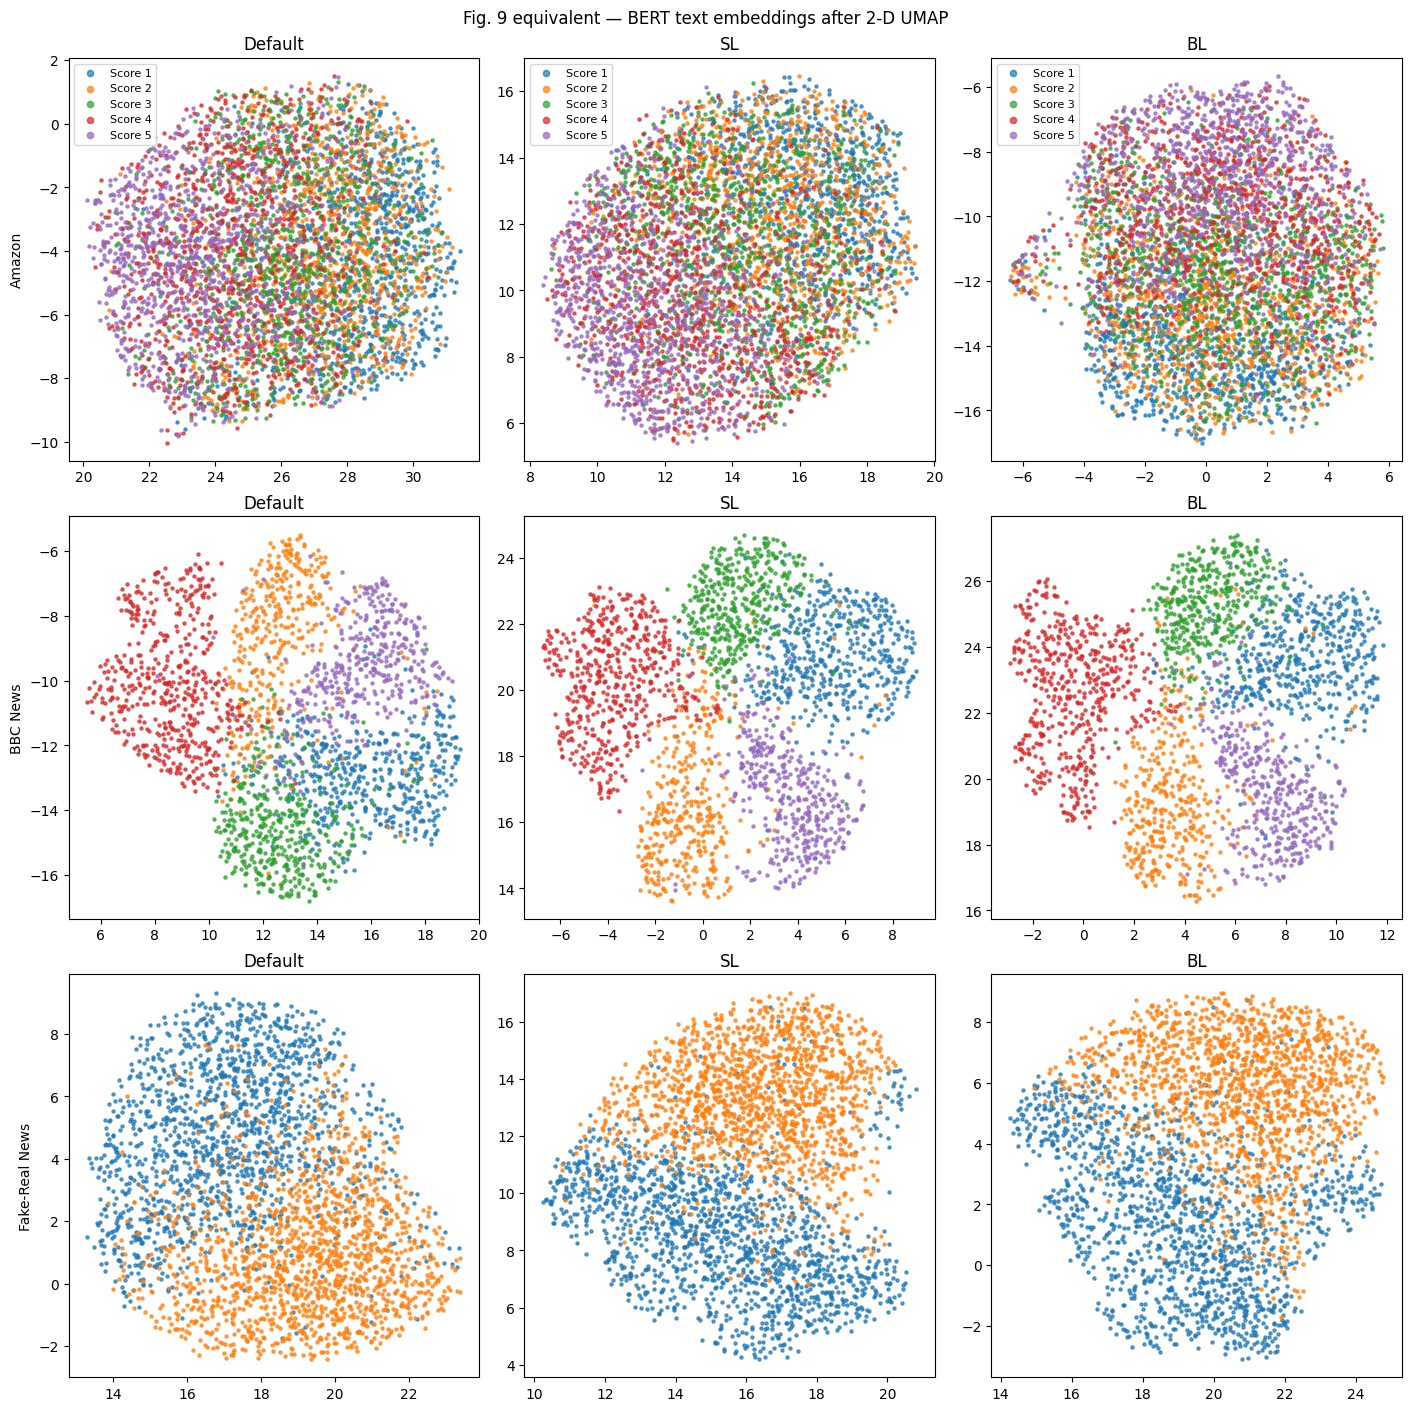

Saved: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\generated_results\figures\fig9_bert_umap_2d.png


In [11]:

LABEL_NAMES = {
    "amazon_5000": {1: "Score 1", 2: "Score 2", 3: "Score 3", 4: "Score 4", 5: "Score 5"},
    "bbc_2250": {1: "business", 2: "entertainment", 3: "politics", 4: "sport", 5: "tech"},
    "Fake_3000": {1: "Fake", 0: "True"},
}

if RUN_VISUALIZATIONS:
    fig, axes = plt.subplots(3, 3, figsize=(14, 14), constrained_layout=True)
    for row_i, dataset_key in enumerate(DATASETS):
        df = load_dataset(dataset_key, QUICK_N if QUICK_TEST else None)
        y = df["cluster"].to_numpy()
        for col_i, method in enumerate(STANDARD_METHODS):
            emb = get_embeddings(dataset_key, "BERT", method, df)
            reducer = umap.UMAP(
                n_neighbors=70,
                n_components=2,
                metric="euclidean",
                min_dist=0.9,
                random_state=UMAP_SEED,
                transform_seed=UMAP_SEED,
            )
            xy = reducer.fit_transform(emb)
            ax = axes[row_i, col_i]
            for label in sorted(np.unique(y)):
                mask = y == label
                ax.scatter(xy[mask, 0], xy[mask, 1], s=5, alpha=0.7, label=LABEL_NAMES[dataset_key].get(label, str(label)))
            ax.set_title(method)
            if col_i == 0:
                ax.set_ylabel(DATASETS[dataset_key]["display"])
            if row_i == 0:
                ax.legend(markerscale=2, fontsize=8)
    fig.suptitle("Fig. 9 equivalent — BERT text embeddings after 2-D UMAP")
    out = FIG_DIR / "fig9_bert_umap_2d.png"
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


## cosine similarity within Fake/True groups

The calculation averages pairwise cosine similarities **excluding the diagonal self-similarities**. With 1,500 items per class, including the diagonal changes the mean only minimally. The paper's reported values are included for side-by-side comparison.


In [12]:

PAPER_TABLE7 = pd.DataFrame([
    ["Fake", "Default", 0.912, 0.949, 0.965, 0.921, 0.978],
    ["Fake", "SL",      0.994, 0.958, 0.988, 0.973, 0.982],
    ["Fake", "BL",      0.971, 0.976, 0.977, 0.983, 0.956],
    ["True", "Default", 0.897, 0.950, 0.965, 0.957, 0.985],
    ["True", "SL",      0.995, 0.981, 0.990, 0.984, 0.990],
    ["True", "BL",      0.974, 0.987, 0.985, 0.987, 0.975],
], columns=["Cluster", "Method", "BERT", "RoBERTa", "DistilBERT", "ALBERT", "MPNET"])


def average_pairwise_cosine(x):
    # Embeddings are already L2-normalized, but cosine_similarity is explicit and robust.
    sim = cosine_similarity(x)
    n = sim.shape[0]
    if n < 2:
        return np.nan
    return (sim.sum() - np.trace(sim)) / (n * (n - 1))


if RUN_TABLE7:
    df_fake = load_dataset("Fake_3000", QUICK_N if QUICK_TEST else None)
    y = df_fake["cluster"].to_numpy()
    rows = []
    for cluster_value, cluster_name in [(1, "Fake"), (0, "True")]:
        mask = y == cluster_value
        for method in STANDARD_METHODS:
            row = {"Cluster": cluster_name, "Method": method}
            for model_name in STANDARD_MODELS:
                emb = get_embeddings("Fake_3000", model_name, method, df_fake)
                row[model_name] = average_pairwise_cosine(emb[mask])
            rows.append(row)
    table7_local = pd.DataFrame(rows)
    display(table7_local.round(3))
    print("Published Table 7:")
    display(PAPER_TABLE7)
    table7_local.to_csv(TABLE_DIR / "table7_cosine_similarity_local.csv", index=False)

    t7_compare = table7_local.merge(PAPER_TABLE7, on=["Cluster", "Method"], suffixes=("_Local", "_Paper"))
    for m in STANDARD_MODELS:
        t7_compare[f"{m}_Delta"] = t7_compare[f"{m}_Local"] - t7_compare[f"{m}_Paper"]
    t7_compare.to_csv(TABLE_DIR / "table7_paper_vs_local.csv", index=False)


Loading cached: Fake_3000__BERT__Default__n3000.npy
Loading cached: Fake_3000__RoBERTa__Default__n3000.npy
Loading cached: Fake_3000__DistilBERT__Default__n3000.npy
Loading cached: Fake_3000__ALBERT__Default__n3000.npy
Loading cached: Fake_3000__MPNET__Default__n3000.npy
Loading cached: Fake_3000__BERT__SL__n3000.npy
Loading cached: Fake_3000__RoBERTa__SL__n3000.npy
Loading cached: Fake_3000__DistilBERT__SL__n3000.npy
Loading cached: Fake_3000__ALBERT__SL__n3000.npy
Loading cached: Fake_3000__MPNET__SL__n3000.npy
Loading cached: Fake_3000__BERT__BL__n3000.npy
Loading cached: Fake_3000__RoBERTa__BL__n3000.npy
Loading cached: Fake_3000__DistilBERT__BL__n3000.npy
Loading cached: Fake_3000__ALBERT__BL__n3000.npy
Loading cached: Fake_3000__MPNET__BL__n3000.npy
Loading cached: Fake_3000__BERT__Default__n3000.npy
Loading cached: Fake_3000__RoBERTa__Default__n3000.npy
Loading cached: Fake_3000__DistilBERT__Default__n3000.npy
Loading cached: Fake_3000__ALBERT__Default__n3000.npy
Loading cached:

,Cluster,Method,BERT,RoBERTa,DistilBERT,ALBERT,MPNET
0,Fake,Default,0.754,0.372,0.785,0.313,0.291
1,Fake,SL,0.826,0.537,0.826,0.487,0.475
2,Fake,BL,0.834,0.528,0.847,0.764,0.371
3,True,Default,0.760,0.356,0.790,0.251,0.241
4,True,SL,0.773,0.448,0.788,0.321,0.342
5,True,BL,0.785,0.442,0.807,0.664,0.296


Published Table 7:


,Cluster,Method,BERT,RoBERTa,DistilBERT,ALBERT,MPNET
0,Fake,Default,0.912,0.949,0.965,0.921,0.978
1,Fake,SL,0.994,0.958,0.988,0.973,0.982
2,Fake,BL,0.971,0.976,0.977,0.983,0.956
3,True,Default,0.897,0.950,0.965,0.957,0.985
4,True,SL,0.995,0.981,0.990,0.984,0.990
5,True,BL,0.974,0.987,0.985,0.987,0.975


## model correlation heatmap

For each of the five SBERT models, we form a performance vector from **ACC, ARI, NMI and SIL** over all three datasets × three methods using K-Means, then compute Pearson correlations between models.


,BERT,RoBERTa,DistilBERT,ALBERT,MPNET
BERT,1.00,0.84,0.98,0.84,0.80
RoBERTa,0.84,1.00,0.77,0.99,0.99
DistilBERT,0.98,0.77,1.00,0.78,0.72
ALBERT,0.84,0.99,0.78,1.00,0.99
MPNET,0.80,0.99,0.72,0.99,1.00


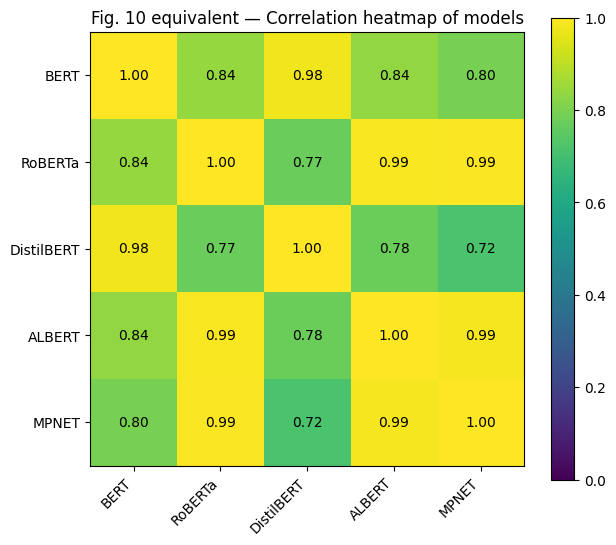

Saved: C:\Users\Aadya Gupta\Desktop\nmims\SEM_VII\Project\generated_results\figures\fig10_model_correlation_heatmap.png


In [13]:
# 12) Fig. 10 model-correlation heatmap
if RUN_VISUALIZATIONS and RUN_FULL_EXPERIMENT:
    km = results[(results.Algorithm == "K-Means") & (results.Model.isin(STANDARD_MODELS)) & (results.Method.isin(STANDARD_METHODS))].copy()
    vectors = {}
    for model_name in STANDARD_MODELS:
        sub = km[km.Model == model_name].sort_values(["Dataset", "Method"])
        vectors[model_name] = sub[["ACC", "ARI", "NMI", "SIL"]].to_numpy().ravel()
    corr_df = pd.DataFrame(vectors).corr()
    display(corr_df.round(2))

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(corr_df.to_numpy(), vmin=0, vmax=1)
    ax.set_xticks(range(len(STANDARD_MODELS)))
    ax.set_yticks(range(len(STANDARD_MODELS)))
    ax.set_xticklabels(STANDARD_MODELS, rotation=45, ha="right")
    ax.set_yticklabels(STANDARD_MODELS)
    for i in range(len(STANDARD_MODELS)):
        for j in range(len(STANDARD_MODELS)):
            ax.text(j, i, f"{corr_df.iloc[i, j]:.2f}", ha="center", va="center")
    fig.colorbar(im, ax=ax)
    ax.set_title("Fig. 10 equivalent — Correlation heatmap of models")
    out = FIG_DIR / "fig10_model_correlation_heatmap.png"
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


In [14]:

def benchmark_one(dataset_key, model_name, method, sample_size):
    full_df = load_dataset(dataset_key)
    n = min(sample_size, len(full_df))
    # Use the first n records to mimic a simple sample-size benchmark.
    df = full_df.iloc[:n].copy().reset_index(drop=True)
    process = psutil.Process(os.getpid())
    clear_accelerator_cache()
    t0 = time.time()
    emb = compute_embeddings(df["text"].tolist(), model_name, method)
    emb = Normalizer().fit_transform(emb)
    elapsed = time.time() - t0
    memory_mb = process.memory_info().rss / 1024**2
    words = df["text"].astype(str).str.split().str.len().sum()
    throughput = words / max(elapsed, 1e-9)
    del emb
    clear_accelerator_cache()
    return elapsed, memory_mb, throughput


if RUN_SCALABILITY_BENCHMARKS:
    bench_rows = []
    for dataset_key in DATASETS:
        full_n = len(pd.read_csv(DATASETS[dataset_key]["path"]))
        sample_sizes = sorted(set([100, 1000, full_n]))
        configurations = [(m, meth) for m in STANDARD_MODELS for meth in STANDARD_METHODS]
        configurations += [("LongFormer", "LongFormer"), ("BigBird", "BigBird")]
        for model_name, method in configurations:
            for n in sample_sizes:
                print("Benchmark:", dataset_key, model_name, method, n)
                runtime, memory_mb, throughput = benchmark_one(dataset_key, model_name, method, n)
                bench_rows.append({
                    "Dataset": dataset_key,
                    "Model": model_name,
                    "Method": method,
                    "SampleSize": n,
                    "RunTimeSeconds": runtime,
                    "MemoryUsageMB": memory_mb,
                    "ThroughputWordsPerSecond": throughput,
                })
    scalability = pd.DataFrame(bench_rows)
    scalability.to_csv(TABLE_DIR / "scalability_runtime_memory_throughput.csv", index=False)
    display(scalability.round(3))


## 14) Final output inventory

After a complete run, the important outputs are written under `generated_results/`:

- `tables/clustering_results_mean_and_std.csv`
- `tables/clustering_results_all_20_seeds.csv`
- `tables/paper_vs_local_clustering.csv`
- `tables/table7_cosine_similarity_local.csv`
- `tables/table7_paper_vs_local.csv`
- `tables/embedding_runtime_memory_throughput.csv`
- `SBERT_full_results.xlsx`
- `figures/fig8_acc_comparison_kmeans.png`
- `figures/fig9_bert_umap_2d.png`
- `figures/fig10_model_correlation_heatmap.png`
- cached `.npy` embeddings under `generated_results/embeddings/`


In [15]:
# List generated outputs
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        try:
            rel = p.relative_to(ROOT)
        except ValueError:
            rel = p
        print(rel)


generated_results\embeddings\amazon_5000__ALBERT__BL__n5000.npy
generated_results\embeddings\amazon_5000__ALBERT__Default__n5000.npy
generated_results\embeddings\amazon_5000__ALBERT__SL__n5000.npy
generated_results\embeddings\amazon_5000__BERT__BL__n5000.npy
generated_results\embeddings\amazon_5000__BERT__Default__n5000.npy
generated_results\embeddings\amazon_5000__BERT__SL__n5000.npy
generated_results\embeddings\amazon_5000__BigBird__BigBird__n5000.npy
generated_results\embeddings\amazon_5000__DistilBERT__BL__n5000.npy
generated_results\embeddings\amazon_5000__DistilBERT__Default__n5000.npy
generated_results\embeddings\amazon_5000__DistilBERT__SL__n5000.npy
generated_results\embeddings\amazon_5000__LongFormer__LongFormer__n5000.npy
generated_results\embeddings\amazon_5000__MPNET__BL__n5000.npy
generated_results\embeddings\amazon_5000__MPNET__Default__n5000.npy
generated_results\embeddings\amazon_5000__MPNET__SL__n5000.npy
generated_results\embeddings\amazon_5000__RoBERTa__BL__n5000.np